##Gold Price Forecasting Using Historical Commodity Prices (Time Series Analysis): A Comparative Study of Machine Learning and Deep Learning Models

Import Libraries and Download Historical Commodity Data from Yahoo Finance

In [1]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

tickers = {
    "Gold": "GC=F",
    "Silver": "SI=F",
    "Platinum": "PL=F",
    "Palladium": "PA=F",
    "Crude_Oil": "CL=F"
}

start_date = "2006-01-01"
end_date = "2026-03-31"  # Exclusive, so data includes March 30, 2026

data = yf.download(
    list(tickers.values()),
    start=start_date,
    end=end_date,
    interval="1d",
    auto_adjust=False,
    progress=False,
    group_by="column"
)

print("Downloaded data shape:", data.shape)
print(data.head())
print(data.tail())

Downloaded data shape: (5096, 30)
Price       Adj Close                                           Close  \
Ticker           CL=F        GC=F PA=F         PL=F   SI=F       CL=F   
Date                                                                    
2006-01-03  63.139999  530.700012  NaN   975.799988  9.087  63.139999   
2006-01-04  63.419998  533.900024  NaN   995.599976  9.102  63.419998   
2006-01-05  62.790001  526.299988  NaN   984.500000  8.809  62.790001   
2006-01-06  64.209999  539.700012  NaN   996.799988  9.112  64.209999   
2006-01-09  63.500000  549.099976  NaN  1012.299988  9.222  63.500000   

Price                                            ...       Open              \
Ticker            GC=F PA=F         PL=F   SI=F  ...       CL=F        GC=F   
Date                                             ...                          
2006-01-03  530.700012  NaN   975.799988  9.087  ...  61.040001  518.599976   
2006-01-04  533.900024  NaN   995.599976  9.102  ...  63.000000  

Download the raw dataset CSV

In [2]:
# Save raw Yahoo Finance data to CSV
raw_file = "gold_commodities_raw_2006_2026.csv"

data.to_csv(raw_file)

print("Raw dataset saved:", raw_file)

# Download the CSV file in Google Colab
from google.colab import files
files.download(raw_file)

Raw dataset saved: gold_commodities_raw_2006_2026.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Extract and align the prices

In [3]:
# Extract closing prices
close_prices = data["Close"].copy()

# Rename ticker symbols to commodity names
close_prices = close_prices.rename(
    columns={
        symbol: name
        for name, symbol in tickers.items()
    }
)

# Standardise and sort dates
close_prices.index = pd.to_datetime(close_prices.index)
close_prices = close_prices.sort_index()
close_prices.index.name = "Date"

# Remove rows where all commodity prices are missing
close_prices = close_prices.dropna(how="all")

# Display date range
print("Available date range:")
print(close_prices.index.min(), "to", close_prices.index.max())

# Display missing values
print("\nMissing values:")
print(close_prices.isna().sum())

# Display observations per commodity
print("\nObservations per commodity:")
print(close_prices.notna().sum())

Available date range:
2006-01-03 00:00:00 to 2026-03-30 00:00:00

Missing values:
Ticker
Crude_Oil      5
Gold           5
Palladium    436
Platinum     528
Silver         5
dtype: int64

Observations per commodity:
Ticker
Crude_Oil    5091
Gold         5091
Palladium    4660
Platinum     4568
Silver       5091
dtype: int64


DATA CLEANING

Handle missing values and download the final dataset

In [4]:
# Create the final modelling dataset
dataset = close_prices.dropna().copy()
dataset.index.name = "Date"

# Check the final dataset
print("Final dataset shape:", dataset.shape)

print("\nDate range:")
print(dataset.index.min(), "to", dataset.index.max())

print("\nMissing values:")
print(dataset.isna().sum())

print("\nFirst 5 rows:")
print(dataset.head())

print("\nLast 5 rows:")
print(dataset.tail())

# Save without downloading again
final_file = "/content/gold_commodities_final_cleaned_2006_2026.csv"
dataset.to_csv(final_file)

print("\nFinal cleaned dataset saved:", final_file)

Final dataset shape: (4319, 5)

Date range:
2006-01-12 00:00:00 to 2026-03-30 00:00:00

Missing values:
Ticker
Crude_Oil    0
Gold         0
Palladium    0
Platinum     0
Silver       0
dtype: int64

First 5 rows:
Ticker      Crude_Oil        Gold   Palladium     Platinum  Silver
Date                                                              
2006-01-12  63.939999  548.299988  275.000000  1023.000000   9.007
2006-01-20  68.349998  553.500000  274.200012  1027.699951   8.880
2006-01-23  68.099998  558.299988  275.799988  1047.800049   9.026
2006-01-24  67.059998  557.700012  272.600006  1052.000000   9.183
2006-01-25  65.849998  562.200012  280.399994  1058.300049   9.465

Last 5 rows:
Ticker       Crude_Oil         Gold    Palladium     Platinum     Silver
Date                                                                    
2026-03-24   92.349998  4402.000000  1411.199951  1892.000000  69.274002
2026-03-25   90.320000  4552.299805  1416.000000  1925.199951  72.361000
2026-03-26 

Inspect the final cleaned dataset

In [6]:
# FINAL DATASET INSPECTION

print("GOLD AND COMMODITY PRICE FORECASTING - DATASET INSPECTION")

print("\n1. Dataset dimensions:")
print(f"Rows: {dataset.shape[0]:,}")
print(f"Columns: {dataset.shape[1]}")

print("\n2. Date range:")
print(f"Start date: {dataset.index.min().date()}")
print(f"End date:   {dataset.index.max().date()}")

print("\n3. Column names:")
print(dataset.columns.tolist())

print("\n4. Data types:")
print(dataset.dtypes)

print("\n5. Missing values:")
print(dataset.isna().sum())

print("\n6. Duplicate dates:")
print(dataset.index.duplicated().sum())

print("\n7. Duplicate rows:")
print(dataset.duplicated().sum())

print("\n8. First five observations:")
display(dataset.head())

print("\n9. Last five observations:")
display(dataset.tail())

print("\n10. Descriptive statistics:")
display(dataset.describe().T.round(2))


GOLD AND COMMODITY PRICE FORECASTING - DATASET INSPECTION

1. Dataset dimensions:
Rows: 4,319
Columns: 5

2. Date range:
Start date: 2006-01-12
End date:   2026-03-30

3. Column names:
['Crude_Oil', 'Gold', 'Palladium', 'Platinum', 'Silver']

4. Data types:
Ticker
Crude_Oil    float64
Gold         float64
Palladium    float64
Platinum     float64
Silver       float64
dtype: object

5. Missing values:
Ticker
Crude_Oil    0
Gold         0
Palladium    0
Platinum     0
Silver       0
dtype: int64

6. Duplicate dates:
0

7. Duplicate rows:
0

8. First five observations:


Ticker,Crude_Oil,Gold,Palladium,Platinum,Silver
Date,,,,,
2006-01-12,63.939999,548.299988,275.000000,1023.000000,9.007
2006-01-20,68.349998,553.500000,274.200012,1027.699951,8.880
2006-01-23,68.099998,558.299988,275.799988,1047.800049,9.026
2006-01-24,67.059998,557.700012,272.600006,1052.000000,9.183
2006-01-25,65.849998,562.200012,280.399994,1058.300049,9.465



9. Last five observations:


Ticker,Crude_Oil,Gold,Palladium,Platinum,Silver
Date,,,,,
2026-03-24,92.349998,4402.000000,1411.199951,1892.000000,69.274002
2026-03-25,90.320000,4552.299805,1416.000000,1925.199951,72.361000
2026-03-26,94.480003,4376.299805,1341.300049,1838.300049,67.670998
2026-03-27,99.639999,4492.500000,1390.900024,1870.599976,69.544998
2026-03-30,102.879997,4526.000000,1418.000000,1885.599976,70.323997



10. Descriptive statistics:


,count,mean,std,min,25%,50%,75%,max
Ticker,,,,,,,,
Crude_Oil,4319.0,71.78,20.95,-37.63,55.61,71.32,87.91,145.29
Gold,4319.0,1663.44,716.76,548.30,1248.20,1468.10,1829.35,5318.40
Palladium,4319.0,1107.09,615.77,171.50,691.15,890.50,1436.80,2985.40
Platinum,4319.0,1187.57,331.64,595.90,933.90,1034.80,1448.90,2852.40
Silver,4319.0,23.47,10.76,8.79,16.84,20.53,27.47,115.08


EDA(Exploratory Data Analysis)

GOLD PRICE LINE PLOT

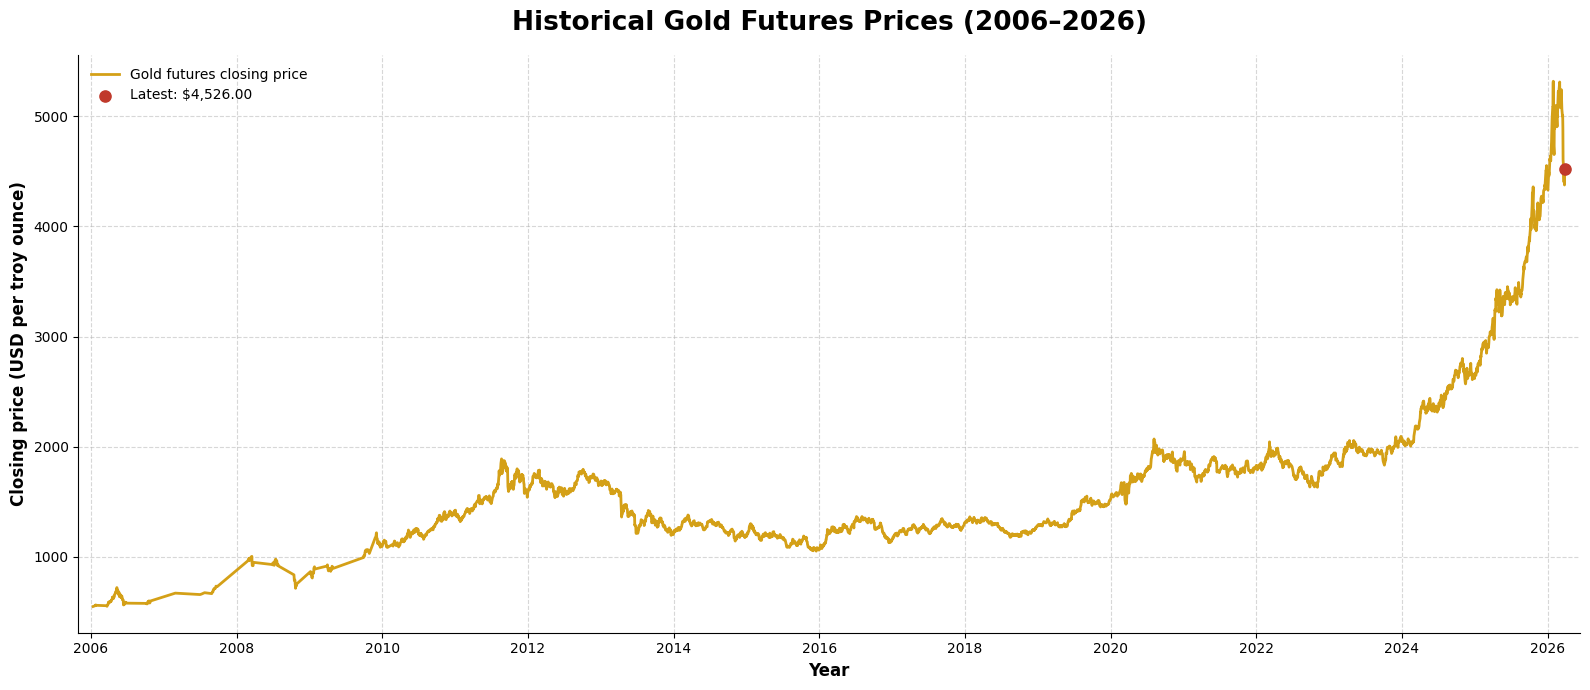

Minimum gold price: $548.30
Maximum gold price: $5,318.40
Latest gold price:  $4,526.00


In [13]:
# GOLD PRICE LINE PLOT

gold = dataset["Gold"].dropna()

fig, ax = plt.subplots(figsize=(16, 7))

ax.plot(
    gold.index,
    gold.values,
    color="#D4A017",
    linewidth=2.0,
    label="Gold futures closing price"
)

# Highlight the latest observation
ax.scatter(
    gold.index[-1],
    gold.iloc[-1],
    color="#C0392B",
    s=65,
    zorder=5,
    label=f"Latest: ${gold.iloc[-1]:,.2f}"
)

ax.set_title(
    "Historical Gold Futures Prices (2006–2026)",
    fontsize=19,
    fontweight="bold",
    pad=18
)

ax.set_xlabel("Year", fontsize=12, fontweight="bold")
ax.set_ylabel("Closing price (USD per troy ounce)", fontsize=12, fontweight="bold")

ax.grid(True, linestyle="--", alpha=0.5)
ax.legend(frameon=False, fontsize=10)
ax.margins(x=0.01)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

print(f"Minimum gold price: ${gold.min():,.2f}")
print(f"Maximum gold price: ${gold.max():,.2f}")
print(f"Latest gold price:  ${gold.iloc[-1]:,.2f}")

**Analysis**: Gold futures prices show a strong overall upward trend from 2006 to 2026, with periods of decline and volatility. Growth accelerated sharply from 2024, reaching a latest plotted price of approximately $4,526 per troy ounce.

Gold Futures Price Trend (2006–2026): Effects of the 2008 Financial Crisis, COVID-19 Pandemic, and 2022 Russia–Ukraine War

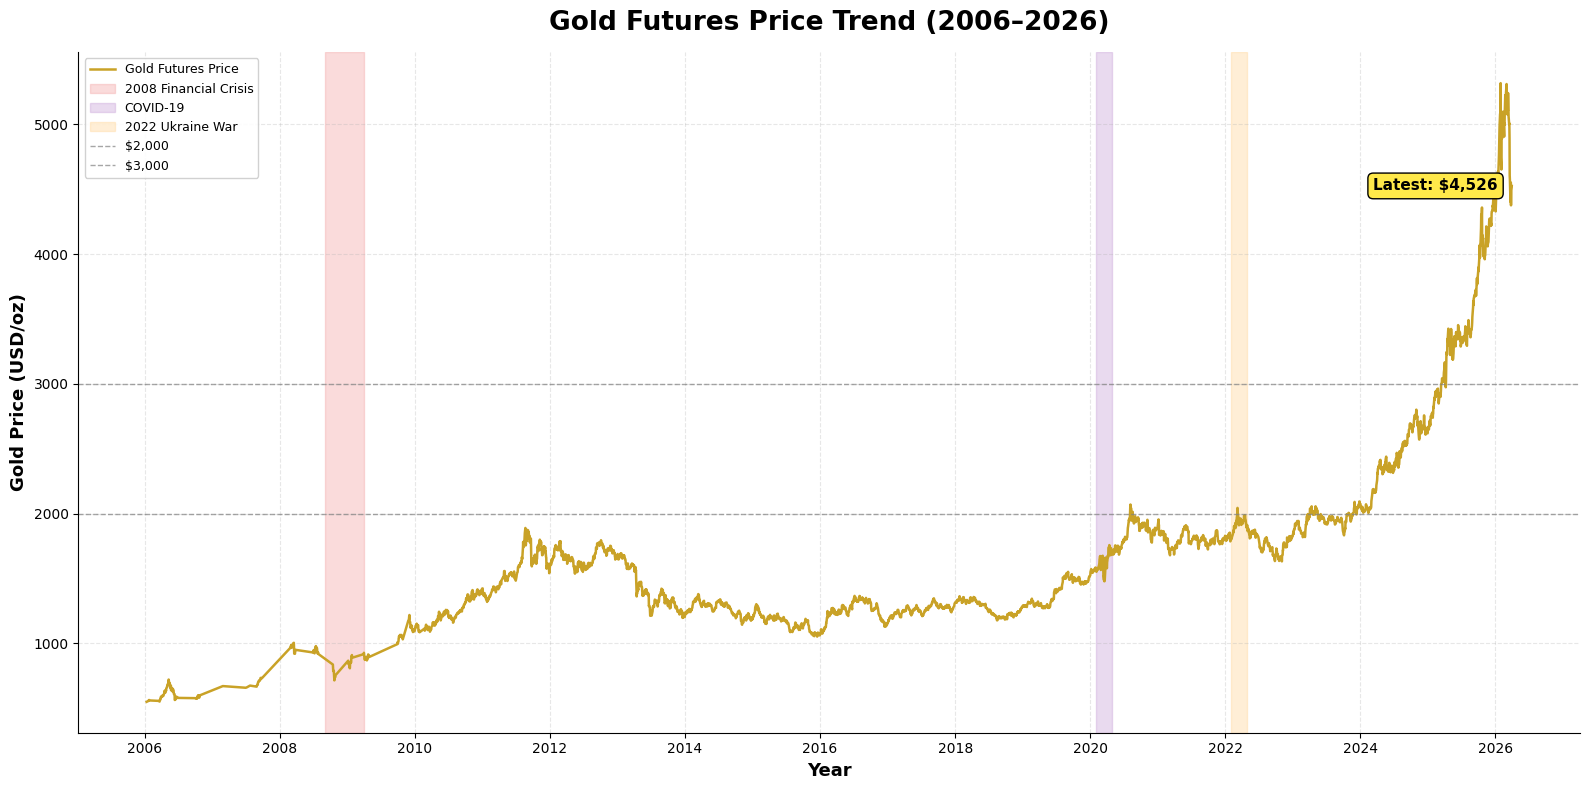

In [12]:
import matplotlib.dates as mdates

# Gold futures closing prices
gold = dataset["Gold"].dropna()

fig, ax = plt.subplots(figsize=(16, 8))

# Gold price line
ax.plot(
    gold.index,
    gold.values,
    color="#C9A227",
    linewidth=1.8,
    label="Gold Futures Price"
)

# Highlight selected historical periods
periods = [
    ("2008-09-01", "2009-03-31", "2008 Financial Crisis", "#F4A6A6"),
    ("2020-02-01", "2020-04-30", "COVID-19", "#C9A3D8"),
    ("2022-02-01", "2022-04-30", "2022 Ukraine War", "#FFD699")
]

for start, end, label, color in periods:
    ax.axvspan(
        pd.Timestamp(start),
        pd.Timestamp(end),
        color=color,
        alpha=0.4,
        label=label
    )

# Horizontal reference lines
for level in [2000, 3000]:
    ax.axhline(
        y=level,
        color="gray",
        linestyle="--",
        linewidth=1,
        alpha=0.7,
        label=f"${level:,.0f}"
    )

# Latest price annotation
latest_date = gold.index[-1]
latest_price = gold.iloc[-1]

ax.annotate(
    f"Latest: ${latest_price:,.0f}",
    xy=(latest_date, latest_price),
    xytext=(-10, 0),
    textcoords="offset points",
    ha="right",
    va="center",
    fontsize=11,
    fontweight="bold",
    bbox=dict(
        boxstyle="round,pad=0.35",
        facecolor="#FFE94A",
        edgecolor="black"
    ),
    annotation_clip=False
)

# Display years on the X-axis
ax.xaxis.set_major_locator(mdates.YearLocator(2))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

# Titles and formatting
ax.set_title(
    "Gold Futures Price Trend (2006–2026)",
    fontsize=19,
    fontweight="bold",
    pad=16
)

ax.set_xlabel("Year", fontsize=13, fontweight="bold")
ax.set_ylabel("Gold Price (USD/oz)", fontsize=13, fontweight="bold")

ax.grid(True, linestyle="--", alpha=0.3)
ax.legend(loc="upper left", fontsize=9, framealpha=0.9)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

**Analysis**: Gold futures prices show a strong long-term upward trend from 2006 to 2026, despite several periods of volatility and correction. Prices declined after peaking around 2011–2012 and remained relatively stable for several years. Further growth occurred around the COVID-19 period, followed by fluctuations during 2022–2023. A sharp rise from 2024 pushed prices above
5,000 before the latest observed value of approximately $4,526 per troy ounce. These movements highlight long-term growth and changing market volatility.

Combined line plot of all five commodities

The next plot shows all five original closing-price series together. Because each commodity has a different price scale, some lines may appear much flatter than others.

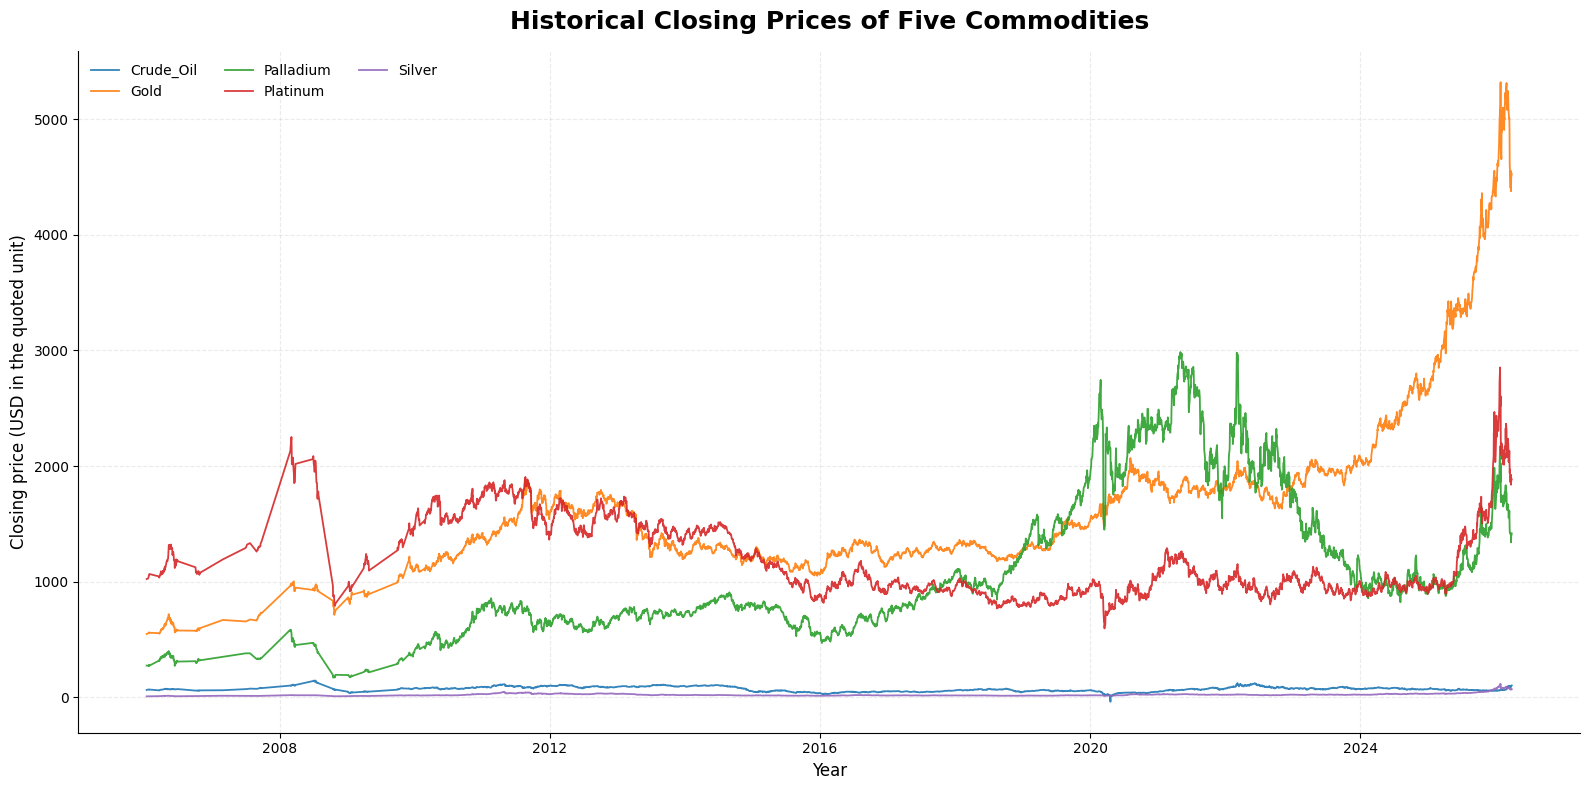

In [14]:
# COMBINED COMMODITY PRICE PLOT

fig, ax = plt.subplots(figsize=(16, 8))

for commodity in dataset.columns:
    ax.plot(
        dataset.index,
        dataset[commodity],
        linewidth=1.3,
        alpha=0.9,
        label=commodity
    )

ax.set_title(
    "Historical Closing Prices of Five Commodities",
    fontsize=18,
    fontweight="bold",
    pad=16
)

ax.set_xlabel("Year", fontsize=12)
ax.set_ylabel("Closing price (USD in the quoted unit)", fontsize=12)

ax.grid(True, linestyle="--", alpha=0.25)
ax.legend(ncol=3, frameon=False, loc="upper left")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

**Interpretation**: Gold shows the strongest upward trend, rising sharply from 2024 to 2026. Palladium and platinum exhibit greater fluctuations, with notable price spikes and declines, while silver and crude oil remain comparatively lower in absolute price. These differences highlight varying price trends and volatility across commodities.

Compare commodity trends on a common scale

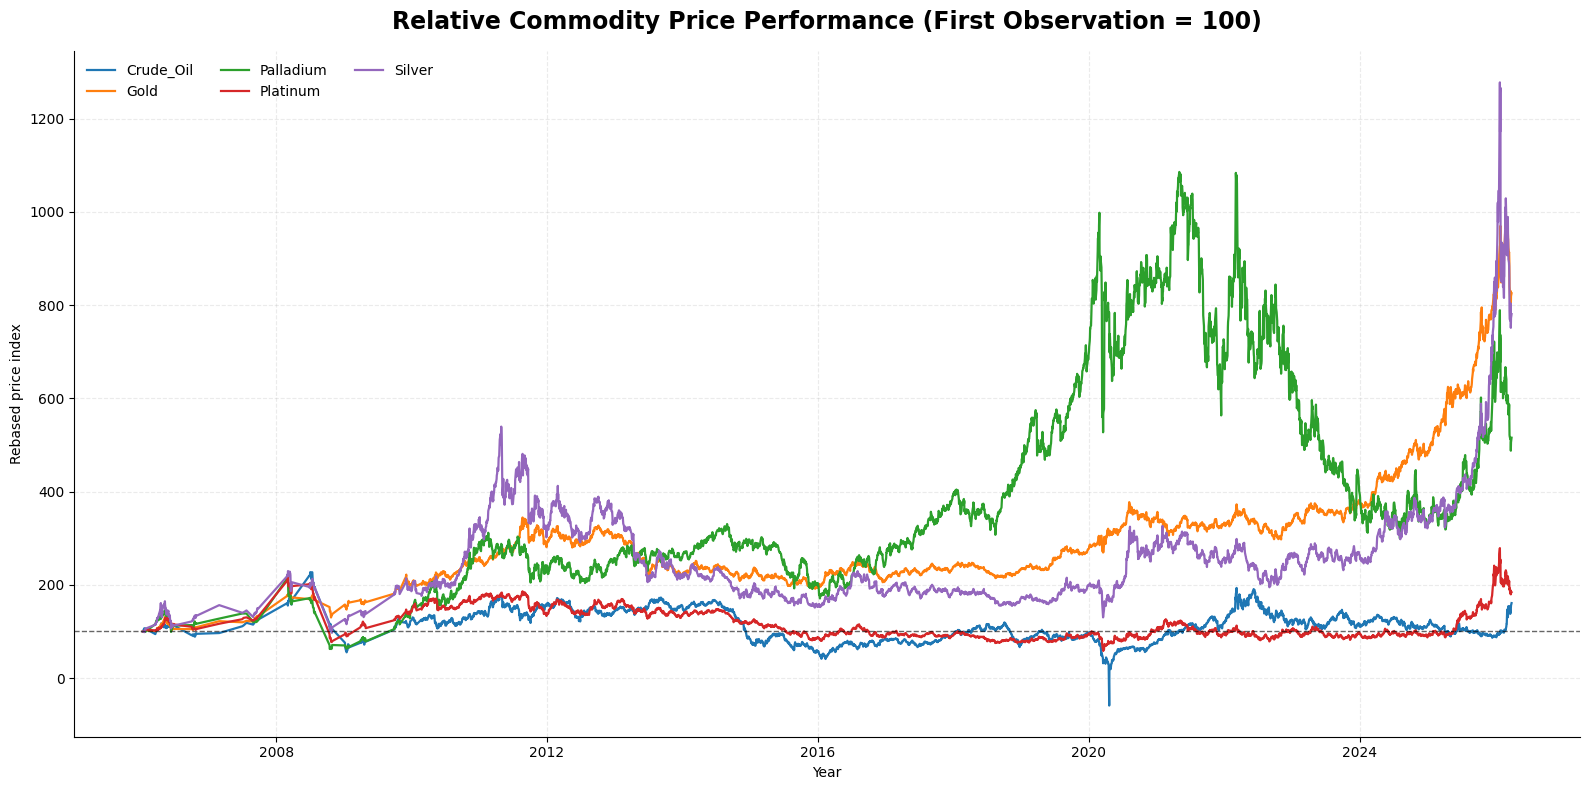

In [15]:
# NORMALISED PRICE COMPARISON


normalised_prices = dataset.div(dataset.iloc[0]).mul(100)

fig, ax = plt.subplots(figsize=(16, 8))

for commodity in normalised_prices.columns:
    ax.plot(
        normalised_prices.index,
        normalised_prices[commodity],
        linewidth=1.6,
        label=commodity
    )

ax.axhline(100, color="black", linestyle="--", linewidth=1, alpha=0.6)

ax.set_title(
    "Relative Commodity Price Performance (First Observation = 100)",
    fontsize=17,
    fontweight="bold",
    pad=16
)

ax.set_xlabel("Year")
ax.set_ylabel("Rebased price index")
ax.legend(ncol=3, frameon=False)
ax.grid(True, linestyle="--", alpha=0.25)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

To compare how much each commodity has changed over time, rebase all five series to 100 at the first date in the cleaned dataset.
This transformation is only for visual comparison. It does not change the original dataset or the target prices used for forecasting.

**Interpretation**: Palladium and silver show substantial relative price fluctuations, with sharp increases around 2011–2012 and 2020–2026. Gold demonstrates strong growth, particularly from 2024, while platinum and crude oil show comparatively moderate long-term gains. Overall, commodity performance varies considerably over time.

Individual commodity price plots

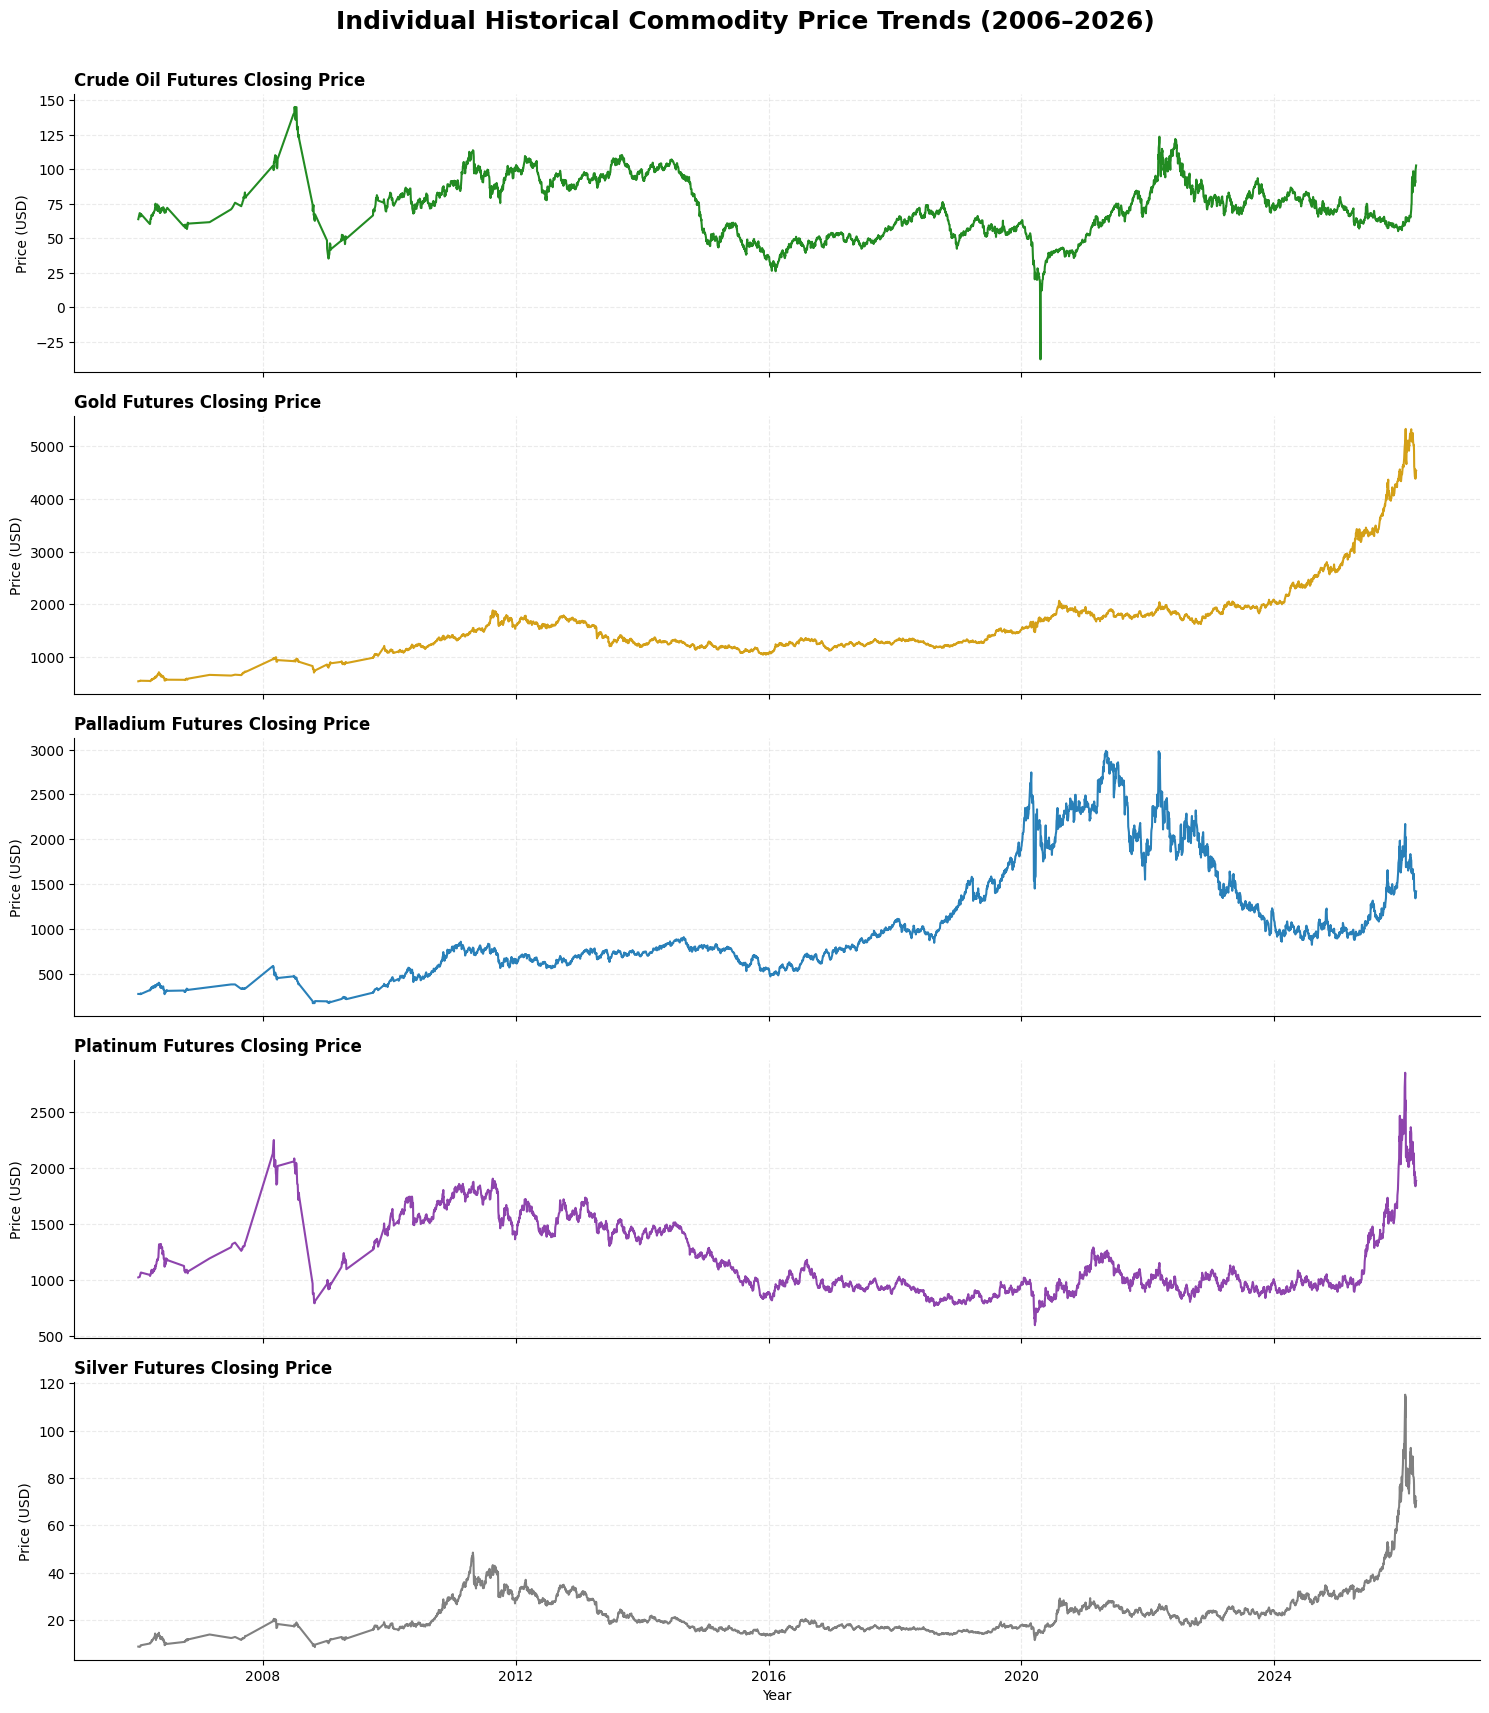

In [29]:
# INDIVIDUAL COMMODITY TRENDS

commodities = dataset.columns.tolist()

# Unique colours for each commodity
commodity_colors = {
    "Gold": "#D4A017",        # Gold
    "Silver": "#808080",      # Silver grey
    "Platinum": "#8E44AD",    # Purple
    "Palladium": "#2980B9",   # Blue
    "Crude_Oil": "#228B22"    # Green
}

fig, axes = plt.subplots(
    nrows=len(commodities),
    ncols=1,
    figsize=(15, 17),
    sharex=True
)

for ax, commodity in zip(axes, commodities):
    ax.plot(
        dataset.index,
        dataset[commodity],
        color=commodity_colors.get(commodity, "#333333"),
        linewidth=1.5
    )

    ax.set_title(
        f"{commodity.replace('_', ' ')} Futures Closing Price",
        fontsize=12,
        fontweight="bold",
        loc="left"
    )

    ax.set_ylabel("Price (USD)")
    ax.grid(True, linestyle="--", alpha=0.25)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

axes[-1].set_xlabel("Year")

plt.suptitle(
    "Individual Historical Commodity Price Trends (2006–2026)",
    fontsize=18,
    fontweight="bold",
    y=1.005
)

plt.tight_layout()
plt.show()

Price distributions

Histograms reveal the distribution of observed price levels.

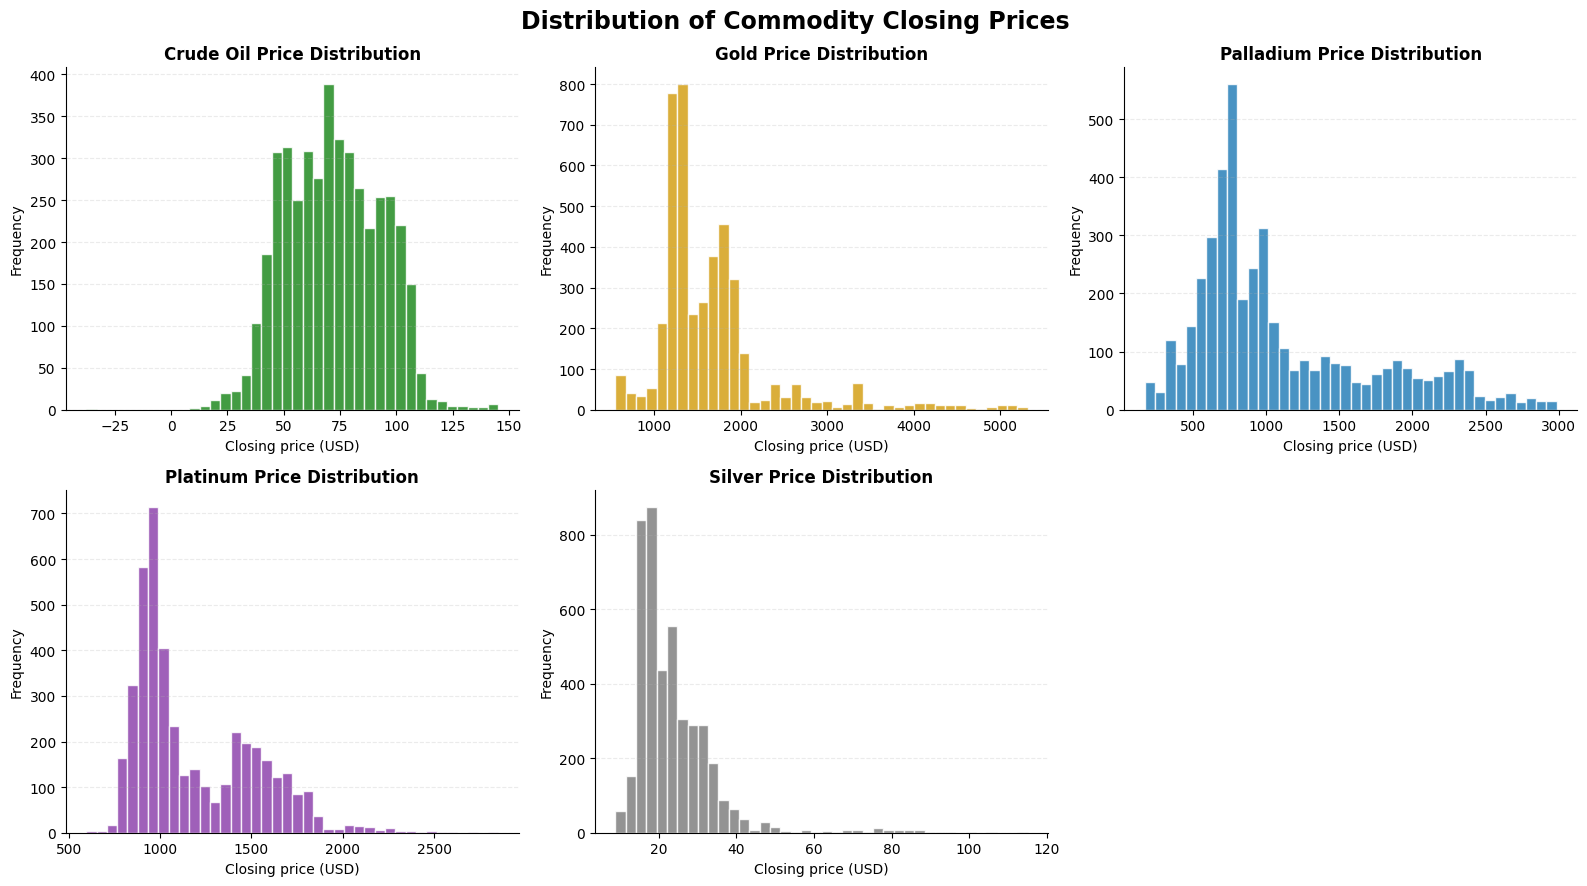

In [30]:
# PRICE DISTRIBUTIONS

commodities = dataset.columns.tolist()

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for i, commodity in enumerate(commodities):
    axes[i].hist(
        dataset[commodity],
        bins=40,
        color=commodity_colors[commodity],
        edgecolor="white",
        alpha=0.85
    )

    axes[i].set_title(
        f"{commodity.replace('_', ' ')} Price Distribution",
        fontweight="bold"
    )
    axes[i].set_xlabel("Closing price (USD)")
    axes[i].set_ylabel("Frequency")
    axes[i].grid(axis="y", linestyle="--", alpha=0.25)

    axes[i].spines["top"].set_visible(False)
    axes[i].spines["right"].set_visible(False)

axes[-1].axis("off")

plt.suptitle(
    "Distribution of Commodity Closing Prices",
    fontsize=17,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

**Interpretation**: Gold, palladium, platinum, and silver price distributions are positively skewed, with long tails toward higher prices. Crude oil prices are more concentrated around the middle range. The distributions reflect varying price ranges and potential extreme market observations across commodities.

Boxplots help identify unusually high or low observations.

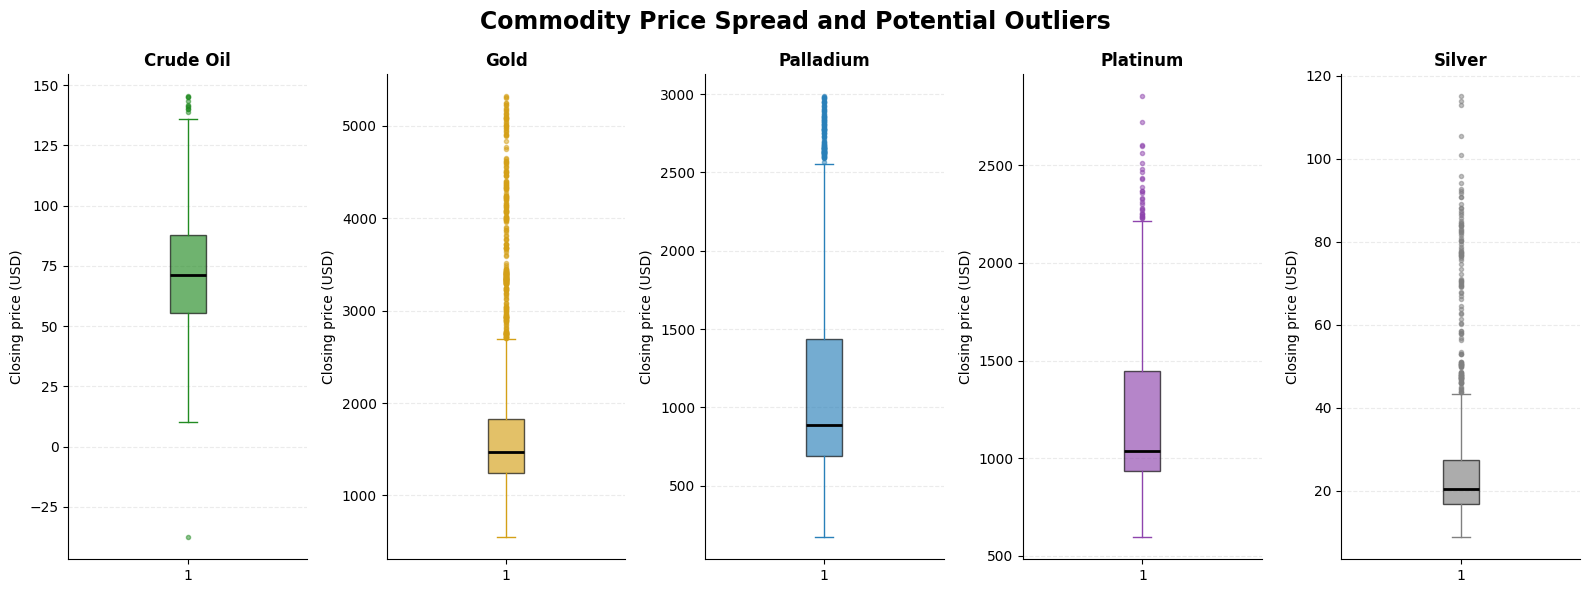

In [31]:
# PRICE BOXPLOTS

fig, axes = plt.subplots(1, len(commodities), figsize=(16, 6))

for ax, commodity in zip(axes, commodities):
    ax.boxplot(
        dataset[commodity],
        patch_artist=True,
        showfliers=True,
        boxprops=dict(
            facecolor=commodity_colors[commodity],
            alpha=0.65
        ),
        medianprops=dict(color="black", linewidth=2),
        whiskerprops=dict(color=commodity_colors[commodity]),
        capprops=dict(color=commodity_colors[commodity]),
        flierprops=dict(
            marker="o",
            markerfacecolor=commodity_colors[commodity],
            markeredgecolor=commodity_colors[commodity],
            markersize=3,
            alpha=0.5
        )
    )

    ax.set_title(commodity.replace("_", " "), fontweight="bold")
    ax.set_ylabel("Closing price (USD)")
    ax.grid(axis="y", linestyle="--", alpha=0.25)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

plt.suptitle(
    "Commodity Price Spread and Potential Outliers",
    fontsize=17,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

**Analysis**: Commodity Price Spread and Potential Outliers
- Crude Oil: Prices are mostly concentrated between 55 and 90 dollars with both high and negative outliers indicating extreme market movements.

- Gold: Prices show a right-skewed distribution, with numerous high-price outliers reflecting recent price increases.
- Palladium: Exhibits substantial price variability, with extreme values approaching $3,000.

- Platinum: Shows a wide price spread, with several high-price outliers above $2,200.
- Silver: Prices are concentrated at lower levels, with a long upper tail and occasional extreme price spikes.
Overall conclusion: All five commodities exhibit varying levels of price variability and potential outliers. These observations should be investigated before removal, as they may represent genuine market events relevant to forecasting.

Daily percentage returns

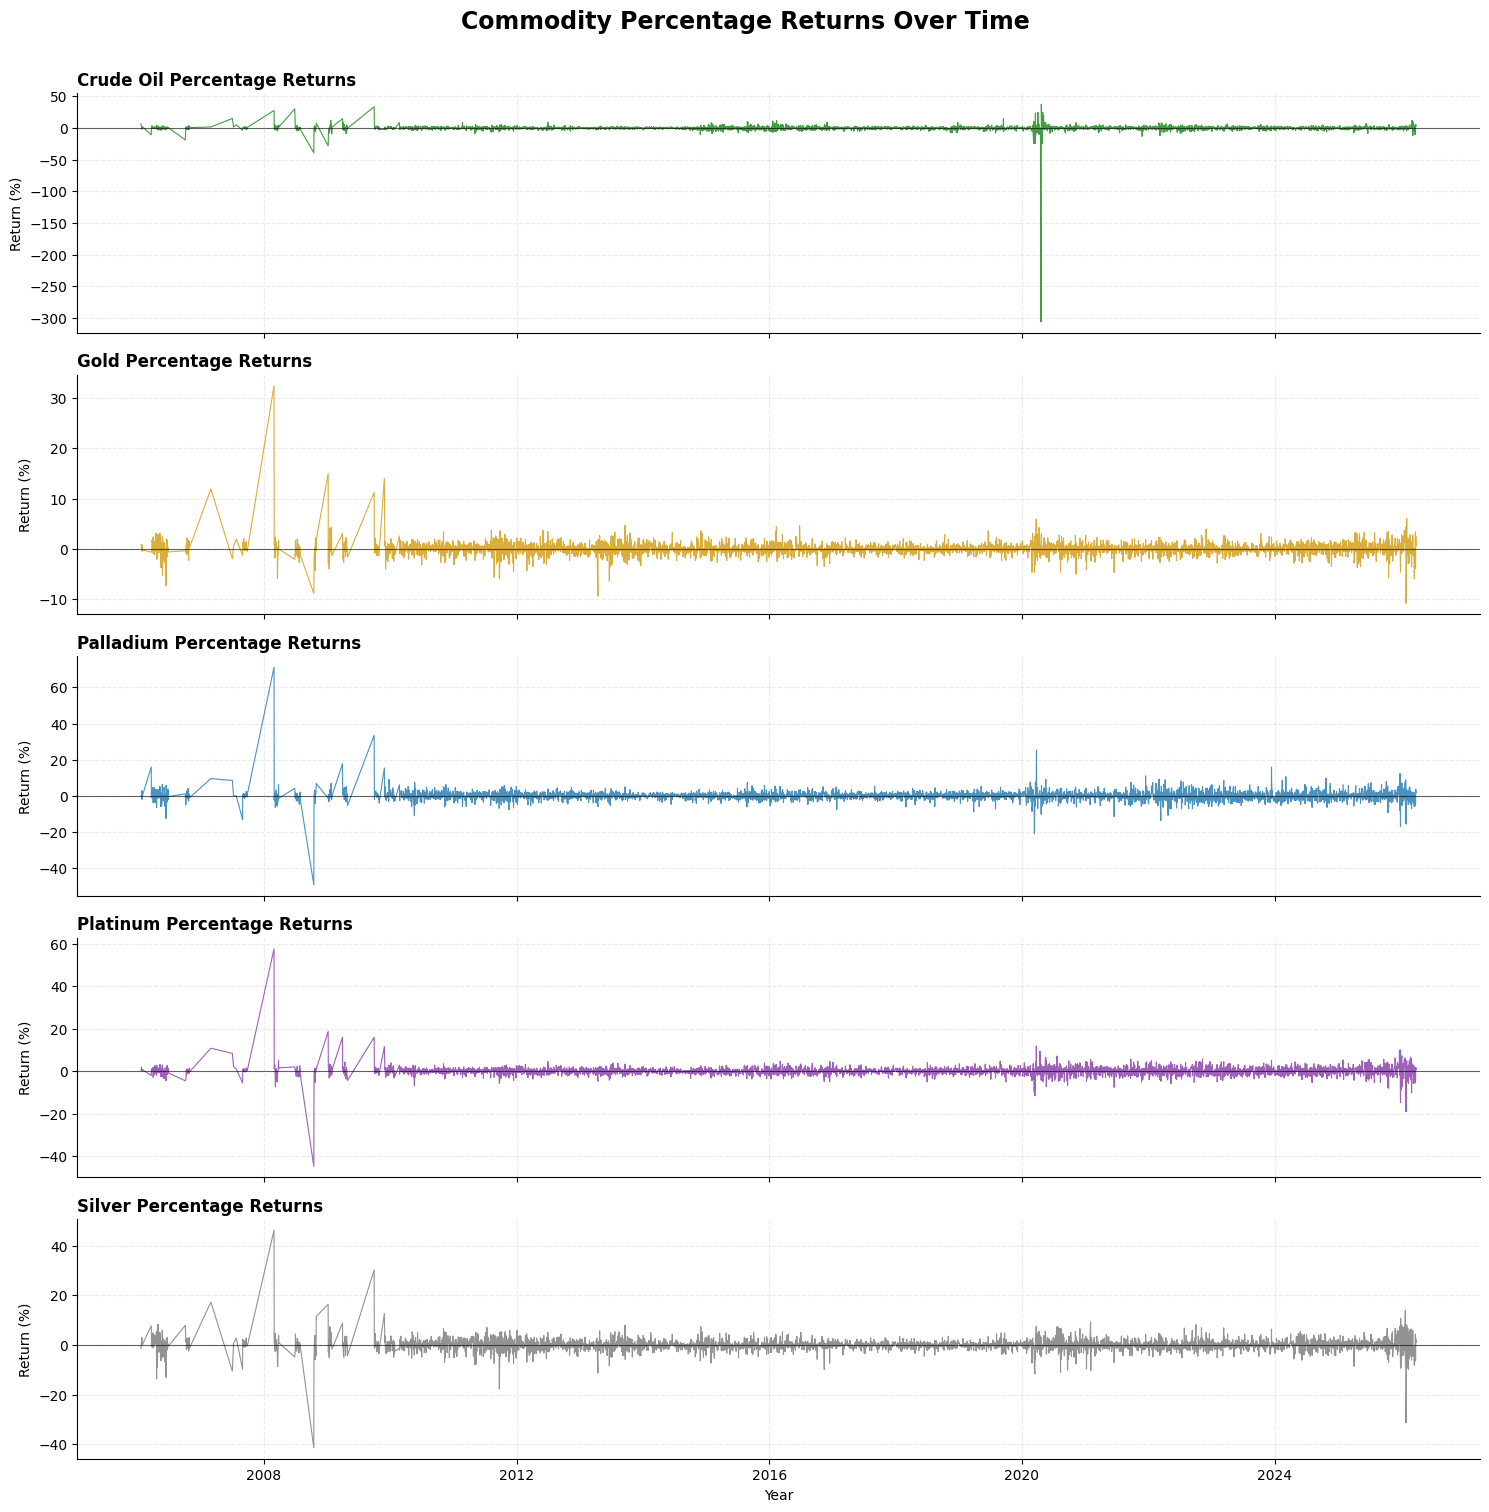

Return statistics (%):


,count,mean,std,min,25%,50%,75%,max
Ticker,,,,,,,,
Crude_Oil,4318.0,-0.0344,5.7926,-305.9661,-1.1808,0.1104,1.2645,37.6623
Gold,4318.0,0.0569,1.2806,-10.7796,-0.4677,0.0472,0.6167,32.4317
Palladium,4318.0,0.0765,2.7956,-49.2370,-1.1767,0.1106,1.3139,71.1758
Platinum,4318.0,0.0370,2.1372,-44.7695,-0.9254,0.0650,0.9536,57.5879
Silver,4318.0,0.0782,2.4534,-41.4772,-0.8953,0.0791,1.0549,46.3178


In [32]:
# PERCENTAGE RETURNS

returns = dataset.pct_change(fill_method=None) * 100
returns = returns.dropna(how="all")

fig, axes = plt.subplots(5, 1, figsize=(15, 15), sharex=True)

for ax, commodity in zip(axes, commodities):
    ax.plot(
        returns.index,
        returns[commodity],
        color=commodity_colors[commodity],
        linewidth=0.8,
        alpha=0.85
    )

    ax.axhline(0, color="black", linewidth=0.8, alpha=0.6)

    ax.set_title(
        f"{commodity.replace('_', ' ')} Percentage Returns",
        loc="left",
        fontweight="bold"
    )

    ax.set_ylabel("Return (%)")
    ax.grid(True, linestyle="--", alpha=0.25)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

axes[-1].set_xlabel("Year")

plt.suptitle(
    "Commodity Percentage Returns Over Time",
    fontsize=17,
    fontweight="bold",
    y=1.005
)

plt.tight_layout()
plt.show()

print("Return statistics (%):")
display(returns.describe().T.round(4))

Important: Because the modelling dataset excludes dates with missing prices, two consecutive rows may not represent consecutive trading days. Returns calculated from dataset can therefore span multiple days. For strict one-trading-day returns, calculate returns from close_prices first and retain only genuinely consecutive observations.

Correlation analysis

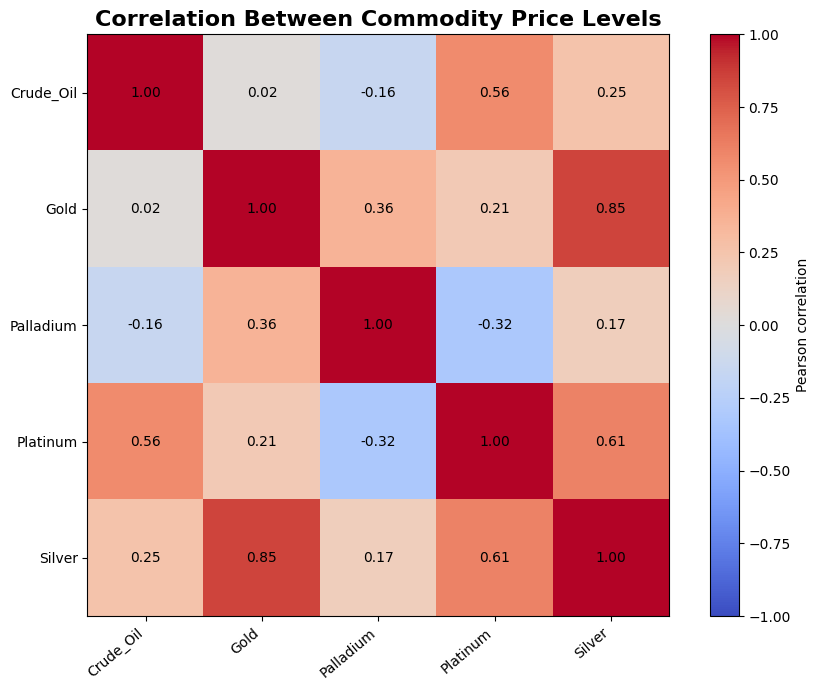

In [34]:
# PRICE CORRELATION

price_corr = dataset.corr()

fig, ax = plt.subplots(figsize=(9, 7))

image = ax.imshow(price_corr, cmap="coolwarm", vmin=-1, vmax=1)

ax.set_xticks(range(len(commodities)))
ax.set_xticklabels(commodities, rotation=40, ha="right")
ax.set_yticks(range(len(commodities)))
ax.set_yticklabels(commodities)

for i in range(len(commodities)):
    for j in range(len(commodities)):
        ax.text(
            j, i, f"{price_corr.iloc[i, j]:.2f}",
            ha="center", va="center", fontsize=10
        )

ax.set_title("Correlation Between Commodity Price Levels", fontsize=16, fontweight="bold")
fig.colorbar(image, ax=ax, label="Pearson correlation")

plt.tight_layout()
plt.show()

**Analysis**: Gold shows a strong positive correlation with Silver (0.85), a weak positive correlation with Platinum (0.21) and a moderate positive correlation with Palladium (0.36), while its correlation with Crude Oil is nearly zero (0.02). Other relationships include Crude Oil–Platinum (0.56), Crude Oil–Silver (0.25), Crude Oil–Palladium (-0.16), Platinum–Silver (0.61), Platinum–Palladium (-0.32), and Palladium–Silver (0.17). No features need to be removed at this stage; all commodities will be retained as candidate predictors and evaluated during model development.

Correlation does not prove that another commodity causes gold prices to change or that it will improve forecasting accuracy. That needs to be tested using your forecasting experiments.

Gold price versus other commodities

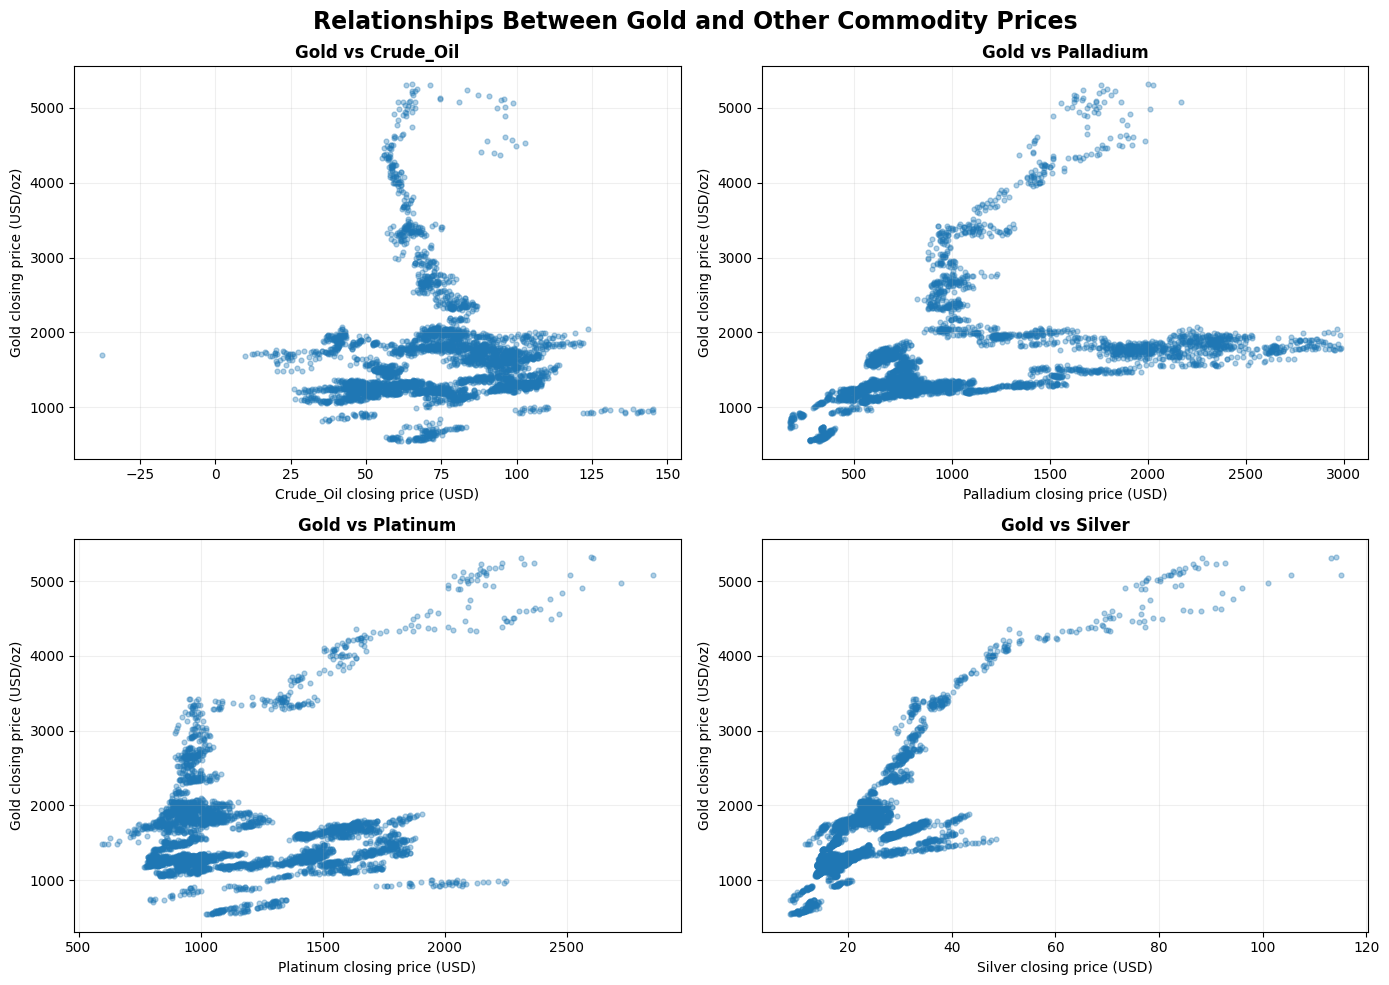

In [24]:
# GOLD VS OTHER COMMODITIES

other_commodities = [c for c in commodities if c != "Gold"]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for ax, commodity in zip(axes, other_commodities):
    ax.scatter(
        dataset[commodity],
        dataset["Gold"],
        alpha=0.35,
        s=12
    )

    ax.set_title(f"Gold vs {commodity}", fontweight="bold")
    ax.set_xlabel(f"{commodity} closing price (USD)")
    ax.set_ylabel("Gold closing price (USD/oz)")
    ax.grid(True, alpha=0.2)

plt.suptitle("Relationships Between Gold and Other Commodity Prices", fontsize=17, fontweight="bold")
plt.tight_layout()
plt.show()

**Analysis**: Relationships Between Gold and Other Commodity Prices
- Gold vs Silver: Shows a clear positive relationship, with gold prices generally increasing as silver prices rise.
- Gold vs Palladium: Displays a generally positive but nonlinear relationship, with considerable variation.
- Gold vs Platinum: Shows a weaker, more scattered relationship, particularly at lower price levels.
- Gold vs Crude Oil: Shows no clear linear pattern, suggesting a weaker direct relationship.

**Overall conclusion**: Silver appears to have the clearest relationship with gold, while the other commodities show more variable patterns. Keep all four commodities as candidate predictors; no features need to be removed at this stage. Their actual forecasting value will be assessed during model evaluation.

Annual Average trends

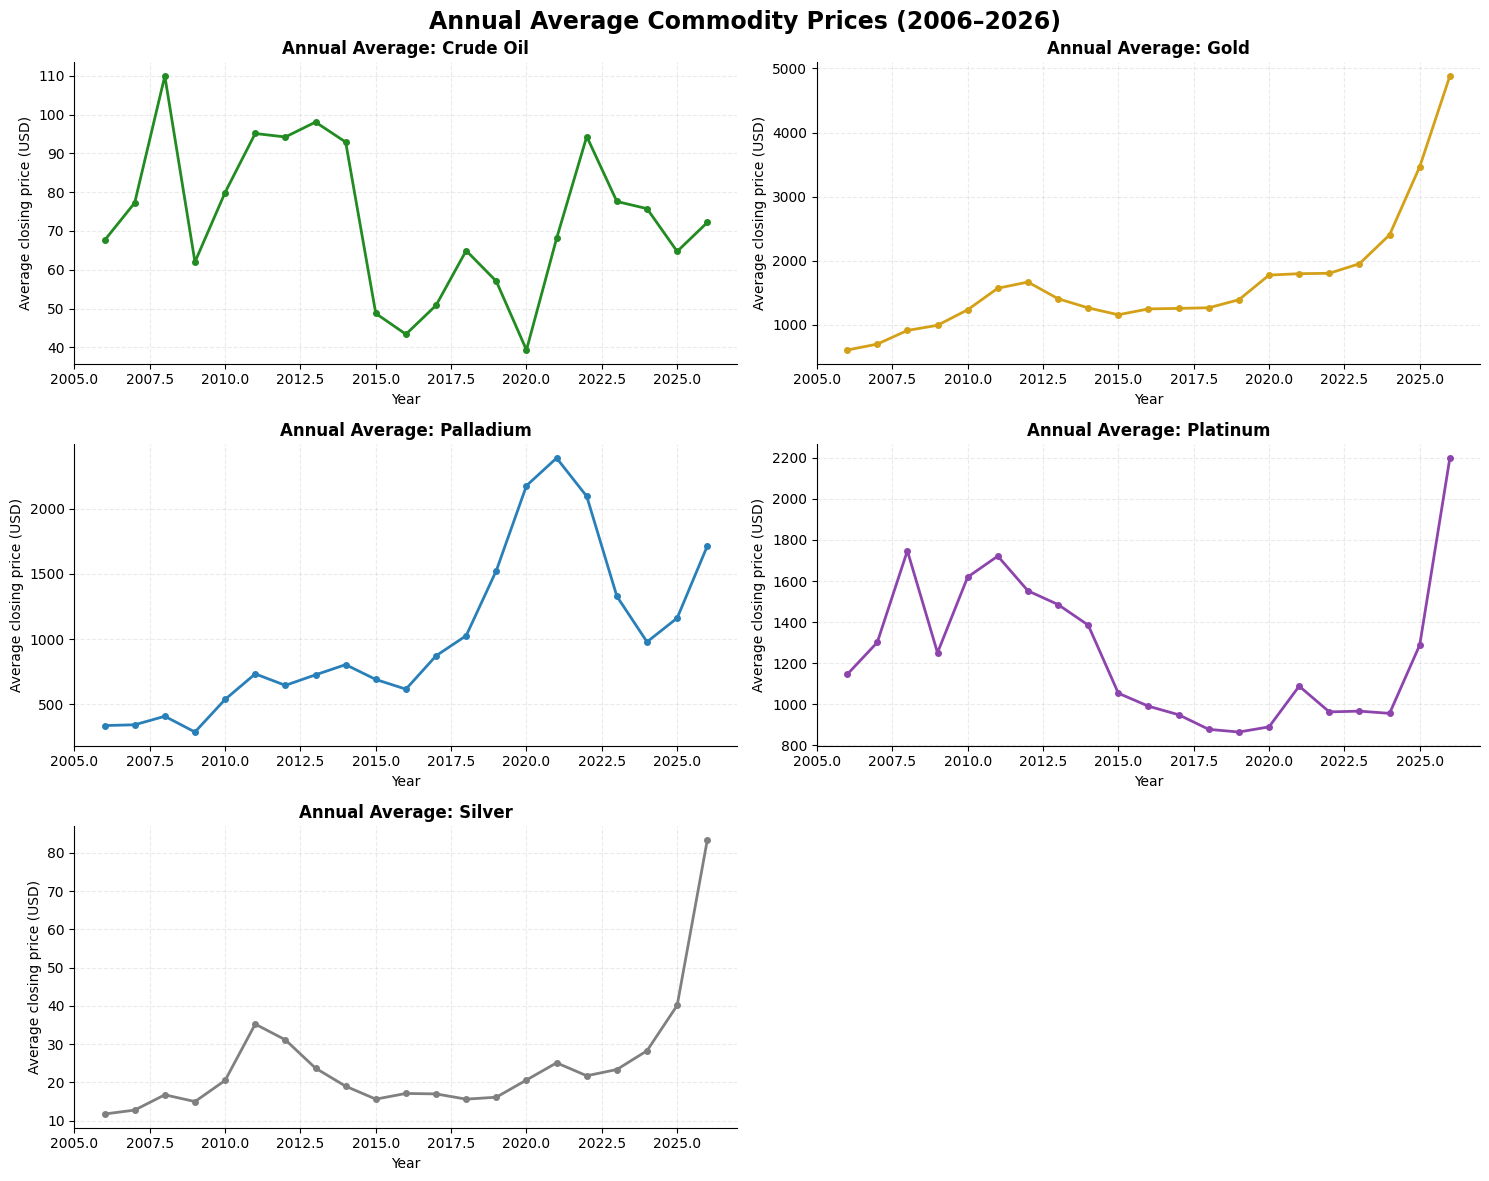

In [35]:
# ANNUAL AVERAGE PRICES

annual_average = dataset.resample("YE").mean()

fig, axes = plt.subplots(3, 2, figsize=(15, 12))
axes = axes.flatten()

for ax, commodity in zip(axes, commodities):
    ax.plot(
        annual_average.index.year,
        annual_average[commodity],
        color=commodity_colors[commodity],
        marker="o",
        markersize=4,
        linewidth=2
    )

    ax.set_title(
        f"Annual Average: {commodity.replace('_', ' ')}",
        fontweight="bold"
    )
    ax.set_xlabel("Year")
    ax.set_ylabel("Average closing price (USD)")
    ax.grid(True, linestyle="--", alpha=0.25)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

axes[-1].axis("off")

plt.suptitle(
    "Annual Average Commodity Prices (2006–2026)",
    fontsize=17,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

**Analysis**: Annual Average Commodity Prices (2006–2026)
- Gold: Shows a strong long-term upward trend, with a sharp increase from 2024 to 2026.
- Crude Oil: Displays considerable fluctuations, including a major decline in 2020 followed by recovery.
- Palladium: Rose significantly between 2018 and 2021, declined afterward, and recovered in 2026.
- Platinum: Experienced a prolonged decline after 2011, followed by a strong increase in 2025–2026.
- Silver: Fluctuated over the years before rising sharply in 2025–2026.

**Overall conclusion**: All commodities show different price trends and volatility patterns. Gold has the clearest sustained upward movement, while palladium and crude oil exhibit greater fluctuations. These differences support retaining all commodities as candidate predictors for further forecasting analysis.